In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [113]:
df = pd.read_csv(r"data/used_car_listings_dataset_from_hatla2ee2026.csv")

In [114]:
df.shape

(13652, 8)

In [115]:
df.dropna(inplace=True)

In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13551 entries, 0 to 13651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         13551 non-null  object 
 1   model         13551 non-null  object 
 2   year          13551 non-null  float64
 3   km            13551 non-null  object 
 4   fuel          13551 non-null  object 
 5   transmission  13551 non-null  object 
 6   price         13551 non-null  object 
 7   description   13551 non-null  object 
dtypes: float64(1), object(7)
memory usage: 952.8+ KB


In [117]:
df

,brand,model,year,km,fuel,transmission,price,description
0,Kia,Rio,2013.0,"122,000 KM",Gas,Automatic,"530,000 EGP",Kia Rio 2013
1,Chevrolet,Aveo,2017.0,"2,017 KM",Gas,Automatic,"395,000 EGP",Chevrolet Aveo 2017
2,Hyundai,Matrix,2006.0,"260,000 KM",Diesel,Automatic,"410,000 EGP",Hyundai Matrix 2006
3,Nissan,Qashqai,2025.0,"50,000 KM",Gas,Automatic,"1,320,000 EGP",Nissan Qashqai 2025
4,Daewoo,Lanos 2,2006.0,"260,000 KM",Gas,Manual,"255,000 EGP",Daewoo Lanos 2 2006
...,...,...,...,...,...,...,...,...
13647,Audi,Q8,2025.0,0 KM,Gas,Automatic,"6,650,000 EGP",Audi Q8 2025
13648,Opel,Astra,2017.0,"200,000 KM",Gas,Automatic,"580,000 EGP",Opel Astra 2017
13649,Suzuki,S Presso,2020.0,0 KM,Gas,Manual,"150,000 EGP",Suzuki S Presso 2020
13650,Nissan,Qashqai,2021.0,"65,000 KM",Gas,Automatic,"1,020,000 EGP",Nissan Qashqai 2021


In [118]:
df['price'] = df['price'].str.replace('EGP', '', regex=False).str.replace(',', '', regex=False).str.strip()


In [119]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

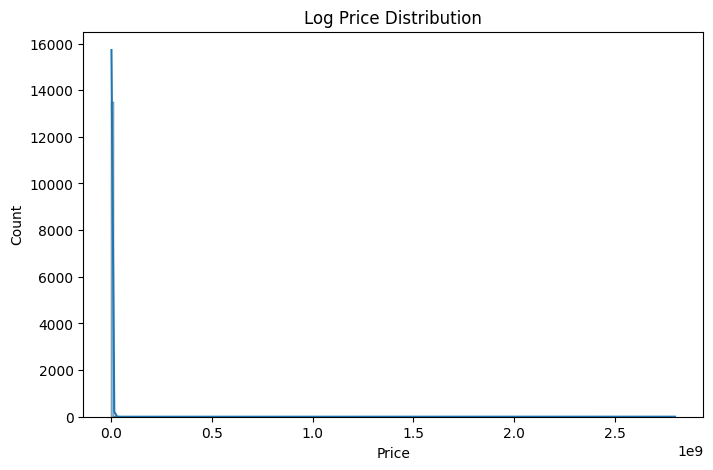

In [120]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Log Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [121]:
df[['price']].describe()

,price
count,1.355100e+04
mean,1.496623e+06
std,2.560178e+07
min,2.000000e+04
25%,4.000000e+05
50%,7.000000e+05
75%,1.350000e+06
max,2.800000e+09


In [122]:
df['price']

0         530000
1         395000
2         410000
3        1320000
4         255000
          ...   
13647    6650000
13648     580000
13649     150000
13650    1020000
13651     565000
Name: price, Length: 13551, dtype: int64

In [123]:
df['km'] = df['km'].str.replace('KM', '', regex=False).str.replace(',', '', regex=False).str.strip()


In [124]:
df['km'] = pd.to_numeric(df['km'], errors='coerce')

In [125]:
df['km'].info()

<class 'pandas.core.series.Series'>
Index: 13551 entries, 0 to 13651
Series name: km
Non-Null Count  Dtype
--------------  -----
13551 non-null  int64
dtypes: int64(1)
memory usage: 211.7 KB


In [126]:
df.drop(df[df['km']==0].index, inplace=True)

In [127]:
df.sort_values(by='price', ascending=True).head(30)

,brand,model,year,km,fuel,transmission,price,description
9818,Fiat,127,1985.0,80000,Gas,Manual,28000,Fiat 127 1985
9033,Suzuki,Van,2017.0,932653,Gas,Manual,30000,Suzuki Van 2017
2340,Chevrolet,T-Series,2005.0,150000,Diesel,Manual,30000,Chevrolet T-Series 2005
8830,Fiat,Siena,2001.0,43000,Gas,Manual,35000,Fiat Siena 2001
3910,Seat,133,1981.0,1000,Gas,Automatic,37000,Seat 133 1981
8386,Fiat,127,1987.0,100000,Gas,Manual,38000,Fiat 127 1987
2098,Fiat,127,1983.0,100000,Gas,Manual,38000,Fiat 127 1983
2777,Fiat,128,1982.0,100000,Gas,Manual,39000,Fiat 128 1982
6375,Fiat,127,1985.0,500000,Gas,Manual,40000,Fiat 127 1985
9414,Fiat,128,1987.0,25000,Gas,Manual,40000,Fiat 128 1987


In [128]:
df['brand'].unique()

array(['Kia', 'Chevrolet', 'Hyundai', 'Nissan', 'Daewoo', 'Renault',
       'Daihatsu', 'Mercedes', 'Subaru', 'Lada', 'Brilliance', 'Citroën',
       'BMW', 'Volkswagen', 'Suzuki', 'Peugeot', 'Mitsubishi', 'Opel',
       'Chery', 'Toyota', 'Fiat', 'MG', 'Skoda', 'Geely', 'Mini', 'Audi',
       'Jetour', 'Jac', 'Speranza', 'Mazda', 'Emgrand', 'Jeep', 'Senova',
       'Seat', 'Alfa', 'Canghe', 'Ford', 'Baic', 'Honda', 'DFSK', 'Byd',
       'Proton', 'Land', 'Porsche', 'Smart', 'Saipa', 'Volvo', 'Gmc',
       'Chrysler', 'Karry', 'Aston', 'Slingshot', 'Ssang', 'Great',
       'Tesla', 'Zotye', 'Isuzu', 'Bestune', 'Changan', 'Haval', 'Avatr',
       'Rolls', 'Kenbo', 'Jaguar', 'Haima', 'Classic', 'Other', 'Datsun',
       'Mahindra', 'Ds', 'Dodge', 'Bugatti', 'Bentley', 'Cupra', 'Faw',
       'Forthing', 'Dongfeng', 'Infiniti', 'Zeekr', 'Kaiyi', 'KGM',
       'Hanteng', 'Lancia', 'GAC', 'Aito', 'Soueast', 'Maserati',
       'li-auto', 'Chana', 'Exeed', 'Keyton', 'Tank', 'Lotus', 'Lexus',
 

In [129]:
top_20_brands = (
    df.groupby('brand')['model']
    .nunique()
    .sort_values(ascending=False)
    .head(20)
)

print(top_20_brands)

brand
Mercedes      88
BMW           54
Hyundai       41
Fiat          35
Volkswagen    28
Kia           25
Renault       25
Peugeot       23
Toyota        23
Geely         19
Chevrolet     19
Suzuki        17
Mitsubishi    17
Skoda         16
Citroën       16
Chery         15
Jeep          14
MG            13
Daewoo        12
Changan       12
Name: model, dtype: int64


In [130]:
df=df[df['brand'].isin(top_20_brands.index)]

In [131]:
len(df)

7559

In [132]:
df['year'] = df['year'].astype(int)

C:\Users\Mazen_PC\AppData\Local\Temp\ipykernel_14940\1483339248.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['year'] = df['year'].astype(int)


In [133]:
df['year'].head()

0    2013
1    2017
2    2006
4    2006
6    2015
Name: year, dtype: int64

In [134]:
df['brand'].value_counts()

brand
Hyundai       917
Mercedes      794
Kia           769
Renault       656
Chevrolet     528
BMW           509
Toyota        382
Peugeot       369
Fiat          352
Skoda         349
Mitsubishi    327
Volkswagen    261
Chery         245
Daewoo        243
MG            236
Suzuki        186
Jeep          156
Citroën       137
Geely         104
Changan        39
Name: count, dtype: int64

In [135]:
price_ranges = {
    "Mercedes":   (150_000, 20_000_000),
    "BMW":        (150_000, 15_000_000),
    "Hyundai":    (100_000, 4_000_000),
    "Fiat":       (80_000, 2_500_000),
    "Volkswagen": (100_000, 5_000_000),
    "Kia":        (100_000, 4_000_000),
    "Renault":    (100_000, 3_000_000),
    "Peugeot":    (100_000, 4_000_000),
    "Toyota":     (150_000, 6_000_000),
    "Geely":      (150_000, 3_000_000),
    "Chevrolet":  (100_000, 3_000_000),
    "Suzuki":     (100_000, 3_000_000),
    "Mitsubishi": (150_000, 4_000_000),
    "Skoda":      (100_000, 5_000_000),
    "Citroën":    (100_000, 4_000_000),
    "Chery":      (150_000, 3_500_000),
    "Jeep":       (200_000, 8_000_000),
    "MG":         (250_000, 3_500_000),
    "Daewoo":     (80_000, 1_000_000),
    "Changan":    (250_000, 3_500_000),
}

In [136]:
df["Price_Original"] = df["price"]

# Apply brand-specific price limits
for brand, (min_price, max_price) in price_ranges.items():
    mask = df["brand"].str.strip().str.casefold() == brand.casefold()

    df.loc[mask, "price"] = (
        df.loc[mask, "price"]
        .clip(lower=min_price, upper=max_price)
    )

C:\Users\Mazen_PC\AppData\Local\Temp\ipykernel_14940\35563244.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Price_Original"] = df["price"]


In [137]:
print(df[["brand", "Price_Original", "price"]].head())

       brand  Price_Original   price
0        Kia          530000  530000
1  Chevrolet          395000  395000
2    Hyundai          410000  410000
4     Daewoo          255000  255000
6    Renault          320000  320000


In [138]:
df['fuel'].value_counts()

fuel
Gas            7038
Diesel          281
Natural Gas     140
Hybrid           61
Electric         39
Name: count, dtype: int64

In [139]:
df.drop('description', axis=1, inplace=True)

C:\Users\Mazen_PC\AppData\Local\Temp\ipykernel_14940\1633226234.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop('description', axis=1, inplace=True)


In [140]:
df

,brand,model,year,km,fuel,transmission,price,Price_Original
0,Kia,Rio,2013,122000,Gas,Automatic,530000,530000
1,Chevrolet,Aveo,2017,2017,Gas,Automatic,395000,395000
2,Hyundai,Matrix,2006,260000,Diesel,Automatic,410000,410000
4,Daewoo,Lanos 2,2006,260000,Gas,Manual,255000,255000
6,Renault,Logan,2015,234000,Gas,Manual,320000,320000
...,...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Gas,Manual,200000,200000
13640,Fiat,Tempra,1997,160000,Gas,Manual,95000,95000
13642,Fiat,Grand Punto,2015,200000,Gas,Automatic,445000,445000
13645,Hyundai,Excel,1996,208000,Gas,Manual,160000,160000


In [141]:
df = df[df["price"] <= 50_000_000].copy()

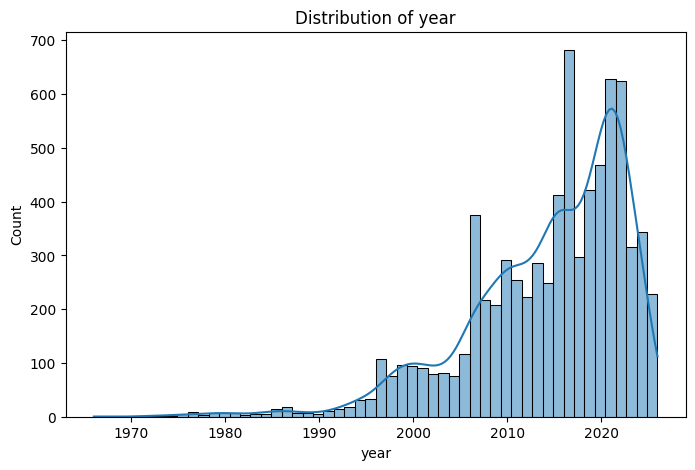

In [142]:

numeric_cols = ['year']

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.show()

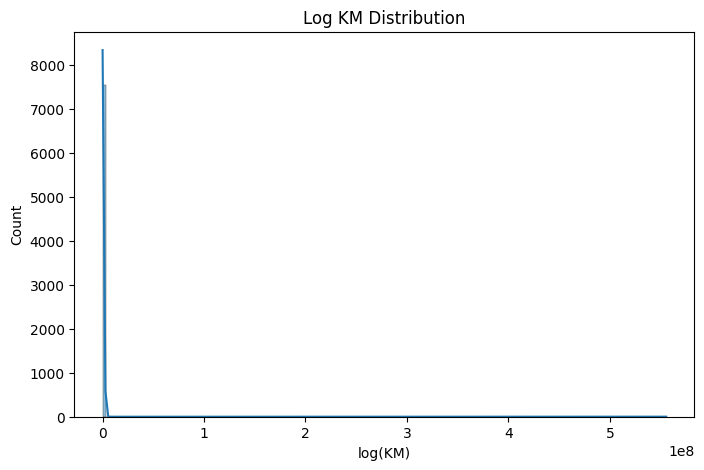

In [143]:
plt.figure(figsize=(8, 5))

sns.histplot(df['km'], kde=True)

plt.title('Log KM Distribution')
plt.xlabel('log(KM)')
plt.ylabel('Count')

plt.show()

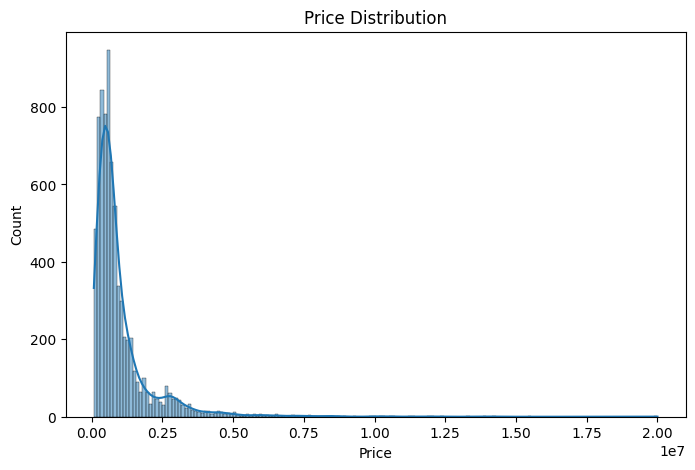

In [144]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [145]:
df['price'].describe()

count    7.559000e+03
mean     1.009048e+06
std      1.190688e+06
min      8.000000e+04
25%      4.000000e+05
50%      6.500000e+05
75%      1.100000e+06
max      2.000000e+07
Name: price, dtype: float64

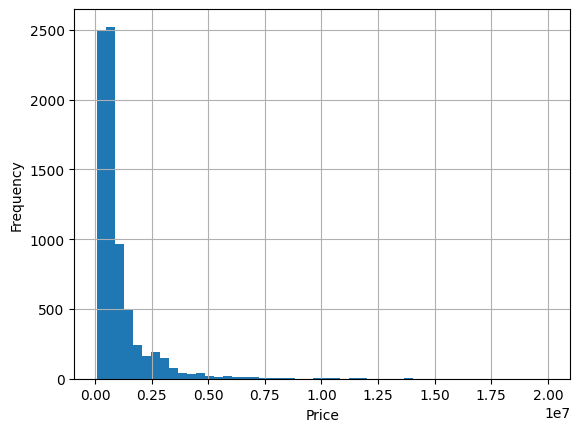

In [146]:
df['price'].hist(bins=50)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

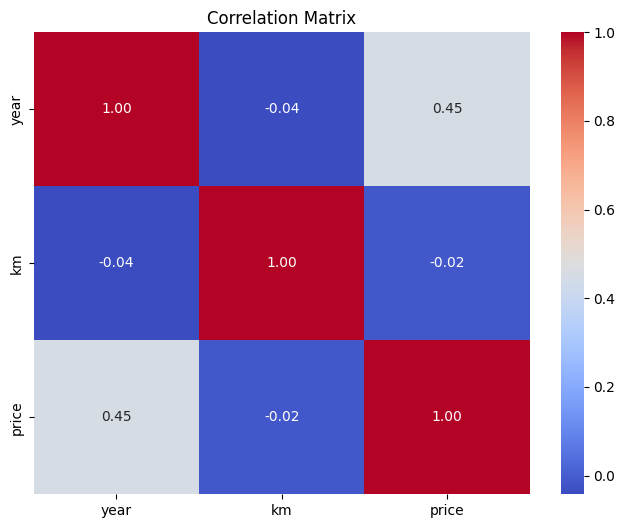

In [147]:

numeric_cols = ['year', 'km', 'price']

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [148]:
fuel_dummies = pd.get_dummies(df['fuel'], prefix='fuel', dtype=int)

df = pd.concat([df, fuel_dummies], axis=1)

df.drop('fuel', axis=1, inplace=True)

In [149]:
df['model'].value_counts()

model
Corolla           253
C 180             228
Lanos             177
Optra             169
Logan             162
                 ... 
Grand Santa Fe      1
Creta SU2           1
GLK                 1
Avensis             1
640                 1
Name: count, Length: 498, dtype: int64

In [150]:
df

,brand,model,year,km,transmission,price,Price_Original,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
0,Kia,Rio,2013,122000,Automatic,530000,530000,0,0,1,0,0
1,Chevrolet,Aveo,2017,2017,Automatic,395000,395000,0,0,1,0,0
2,Hyundai,Matrix,2006,260000,Automatic,410000,410000,1,0,0,0,0
4,Daewoo,Lanos 2,2006,260000,Manual,255000,255000,0,0,1,0,0
6,Renault,Logan,2015,234000,Manual,320000,320000,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Manual,200000,200000,0,0,1,0,0
13640,Fiat,Tempra,1997,160000,Manual,95000,95000,0,0,1,0,0
13642,Fiat,Grand Punto,2015,200000,Automatic,445000,445000,0,0,1,0,0
13645,Hyundai,Excel,1996,208000,Manual,160000,160000,0,0,1,0,0


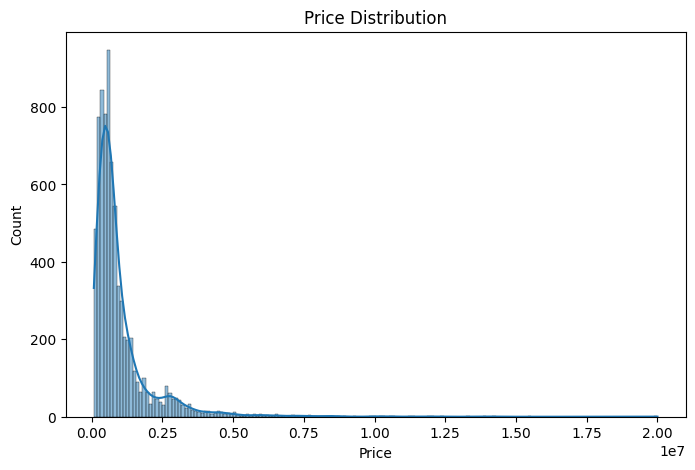

In [151]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [152]:
x=df.drop(['price', 'Price_Original'], axis=1)
y=df['price']

In [153]:
x

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
0,Kia,Rio,2013,122000,Automatic,0,0,1,0,0
1,Chevrolet,Aveo,2017,2017,Automatic,0,0,1,0,0
2,Hyundai,Matrix,2006,260000,Automatic,1,0,0,0,0
4,Daewoo,Lanos 2,2006,260000,Manual,0,0,1,0,0
6,Renault,Logan,2015,234000,Manual,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Manual,0,0,1,0,0
13640,Fiat,Tempra,1997,160000,Manual,0,0,1,0,0
13642,Fiat,Grand Punto,2015,200000,Automatic,0,0,1,0,0
13645,Hyundai,Excel,1996,208000,Manual,0,0,1,0,0


In [154]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [155]:
scaler = StandardScaler()

x_train[['year', 'km']] = scaler.fit_transform(x_train[['year', 'km']])
x_test[['year', 'km']] = scaler.transform(x_test[['year', 'km']])
x_train["transmission"] = x_train["transmission"].map({"Manual": 0,"Automatic": 1})


In [156]:
x_train["transmission"] = x_train["transmission"].map({"Manual": 0,"Automatic": 1})

x_test["transmission"] = x_test["transmission"].map({"Manual": 0,"Automatic": 1})

In [157]:
x_train

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
1392,Mercedes,C 180,-1.450404,0.001388,NaN,0,0,0,1,0
9558,Jeep,Renegade,-4.393240,0.010215,NaN,0,0,1,0,0
10248,BMW,X6,1.139292,-0.033259,NaN,0,0,1,0,0
7113,Peugeot,408,1.257005,-0.034577,NaN,0,0,1,0,0
3999,Chevrolet,Optra,-0.273270,-0.000720,NaN,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
9273,Mitsubishi,Pajero,0.550725,-0.017451,NaN,0,0,1,0,0
9341,Chevrolet,Lanos,-0.037843,-0.016133,NaN,0,0,1,0,0
9632,MG,ZS,1.257005,-0.035696,NaN,0,0,1,0,0
1611,MG,6,0.786151,-0.022720,NaN,0,0,1,0,0


In [158]:
df['brand'].value_counts()

brand
Hyundai       917
Mercedes      794
Kia           769
Renault       656
Chevrolet     528
BMW           509
Toyota        382
Peugeot       369
Fiat          352
Skoda         349
Mitsubishi    327
Volkswagen    261
Chery         245
Daewoo        243
MG            236
Suzuki        186
Jeep          156
Citroën       137
Geely         104
Changan        39
Name: count, dtype: int64

In [159]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

x_train_encoded = encoder.fit_transform(x_train[['brand', 'model']])
x_test_encoded = encoder.transform(x_test[['brand', 'model']])

In [160]:
x_train2 = pd.concat([x_train.drop(columns=['brand', 'model']).reset_index(drop=True), pd.DataFrame(x_train_encoded)],axis=1)

x_test2 = pd.concat([x_test.drop(columns=['brand', 'model']).reset_index(drop=True),pd.DataFrame(x_test_encoded)],axis=1)

In [161]:
x_train

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
1392,Mercedes,C 180,-1.450404,0.001388,NaN,0,0,0,1,0
9558,Jeep,Renegade,-4.393240,0.010215,NaN,0,0,1,0,0
10248,BMW,X6,1.139292,-0.033259,NaN,0,0,1,0,0
7113,Peugeot,408,1.257005,-0.034577,NaN,0,0,1,0,0
3999,Chevrolet,Optra,-0.273270,-0.000720,NaN,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
9273,Mitsubishi,Pajero,0.550725,-0.017451,NaN,0,0,1,0,0
9341,Chevrolet,Lanos,-0.037843,-0.016133,NaN,0,0,1,0,0
9632,MG,ZS,1.257005,-0.035696,NaN,0,0,1,0,0
1611,MG,6,0.786151,-0.022720,NaN,0,0,1,0,0


In [162]:
x_train2

,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas,0,1,...,491,492,493,494,495,496,497,498,499,500
0,-1.450404,0.001388,NaN,0,0,0,1,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-4.393240,0.010215,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.139292,-0.033259,NaN,0,0,1,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.257005,-0.034577,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.273270,-0.000720,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6042,0.550725,-0.017451,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6043,-0.037843,-0.016133,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6044,1.257005,-0.035696,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6045,0.786151,-0.022720,NaN,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [163]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [164]:
model = XGBRegressor(n_estimators=500,learning_rate=0.1,max_depth=6,subsample=0.8,colsample_bytree=0.8,random_state=42)

model.fit(x_train2, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [165]:
y_pred = model.predict(x_test2)

In [166]:
mae_xgboost = mean_absolute_error(y_test, y_pred)
rmse_xgboost = mean_squared_error(y_test, y_pred) ** 0.5
r2_xgboost = r2_score(y_test, y_pred)

print("MAE:", mae_xgboost)
print("RMSE:", rmse_xgboost)
print("R2:", r2_xgboost)

MAE: 130426.1171875
RMSE: 310062.2789569863
R2: 0.9209579229354858
